# Assignment 6: Knock Airport Weather Analysis

In [1]:
import io
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (14, 5), "axes.titlesize": 14, "axes.labelsize": 11, "figure.dpi": 100})

## Loading the Data

In [2]:
URL = "https://clidata.met.ie/cli/climate_data/webdata/hly4935.csv"

resp = requests.get(URL, timeout=60)
resp.raise_for_status()
lines = resp.text.splitlines()

# Skip the metadata block: the tables starts at the line beginning with "date"
start = next(i for i, line in enumerate(lines) if line.lower().startswith("date,"))
df = pd.read_csv(io.StringIO("\n".join(lines[start:])), low_memory=False)

assert "wdsp" in df.columns, "Wrong file: need the hourly data (hly4935.csv)"
df.head()

,date,ind,rain,ind.1,temp,ind.2,wetb,dewpt,vappr,rhum,...,ind.3,wdsp,ind.4,wddir,ww,w,sun,vis,clht,clamt
0,10-apr-1996 14:00,111,0.0,111,11.5,111,8.1,3.9,0.0,0,...,111,0,111,0,25,81,0.0,35000,32,5
1,31-jul-1996 08:00,111,0.0,111,11.5,111,11.1,10.7,0.0,0,...,111,0,111,0,25,82,0.0,40000,45,5
2,31-jul-1996 09:00,111,0.0,111,11.6,111,10.7,9.8,0.0,0,...,111,0,111,0,80,81,0.0,8000,32,7
3,31-jul-1996 10:00,111,0.0,111,12.9,111,11.3,9.8,0.0,0,...,111,0,111,0,25,82,0.0,28000,35,6
4,31-jul-1996 11:00,111,0.0,111,14.5,111,10.8,7.0,0.0,0,...,111,0,111,0,2,11,0.0,40000,40,6


## Cleaning the data

In [3]:
df["date"] = pd.to_datetime(df["date"], format="%d-%b-%Y %H:%M", errors="coerce")
df = df.dropna(subset=["date"]).set_index("date").sort_index()

# Blank strings in the csv becomes NaN 
temp = pd.to_numeric(df["temp"], errors="coerce").asfreq("h")
wind = pd.to_numeric(df["wdsp"], errors="coerce").asfreq("h")

print(f"{temp.index.min():%d %b %Y} to {temp.index.max():%d %b %Y}")
print(f"Missing temperature: {temp.isna().sum():,} hours")
print(f"Missing windspeed:   {wind.isna().sum():,} hours ({wind.isna().mean():.1%})")

10 Apr 1996 to 01 Nov 2026
Missing temperature: 2,681 hours
Missing windspeed:   2,731 hours (1.0%)


## Temperature plot

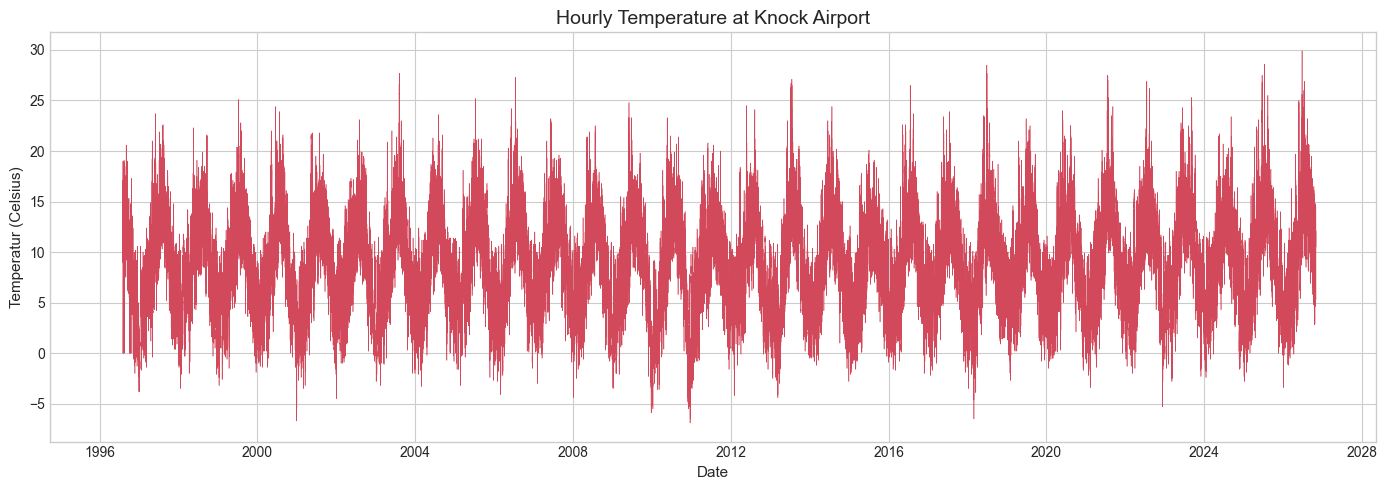

In [4]:
fig, ax = plt.subplots()
ax.plot(temp.index, temp, color="#d1495b", lw=0.4)
ax.set(title="Hourly Temperature at Knock Airport", xlabel="Date", ylabel="Temperatur (Celsius)")
plt.tight_layout()
plt.show()

## Daily Mean Temperature plot

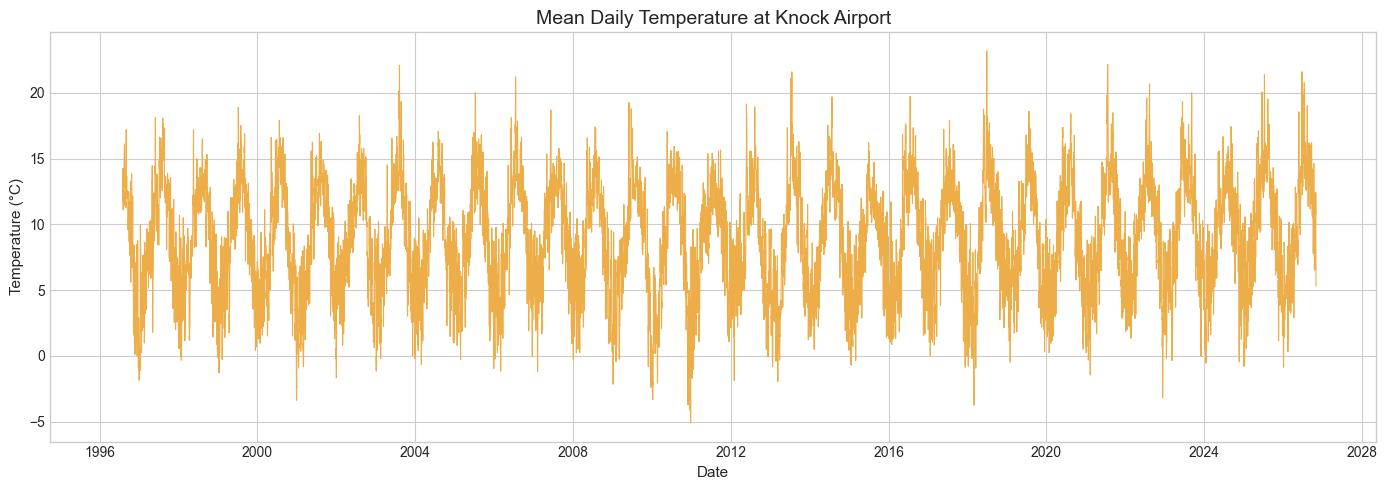

In [5]:
daily_temp = temp.resample("D").mean()

fig, ax = plt.subplots()
ax.plot(daily_temp.index, daily_temp, color="#edae49", lw=0.8)
ax.set(title="Mean Daily Temperature at Knock Airport", xlabel="Date", ylabel="Temperature (°C)")
plt.tight_layout()
plt.show()

## Monthly Mean Temperature plot

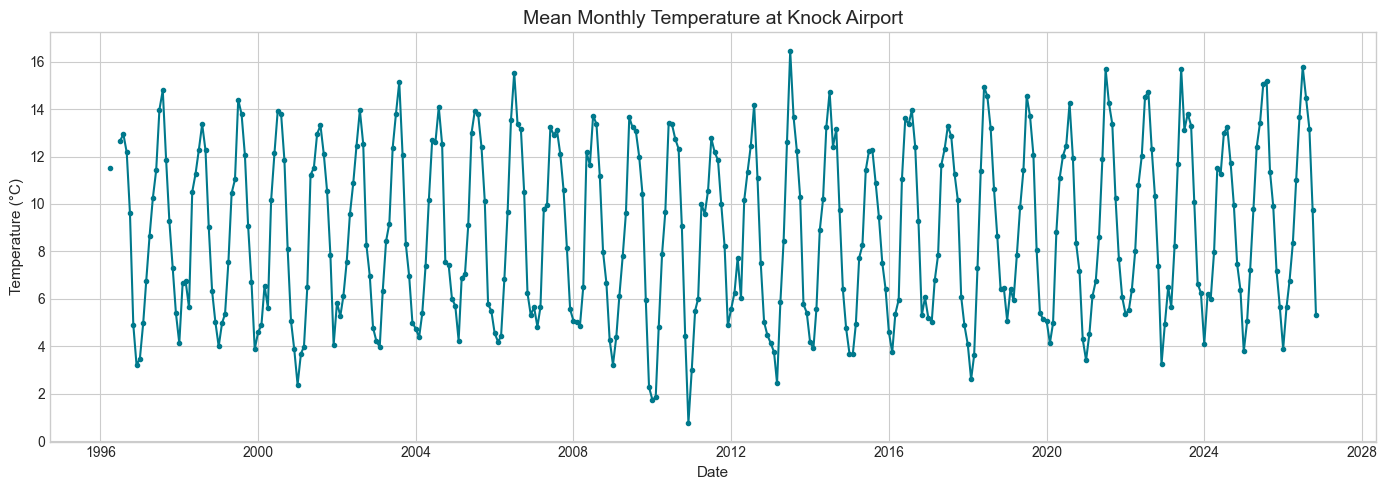

In [6]:
monthly_temp = temp.resample("MS").mean()

fig, ax = plt.subplots()
ax.plot(monthly_temp.index, monthly_temp, color="#00798c", lw=1.5, marker="o", ms=3)
ax.set(title="Mean Monthly Temperature at Knock Airport", xlabel="Date", ylabel="Temperature (°C)")
plt.tight_layout()
plt.show()

## Windspeed plot

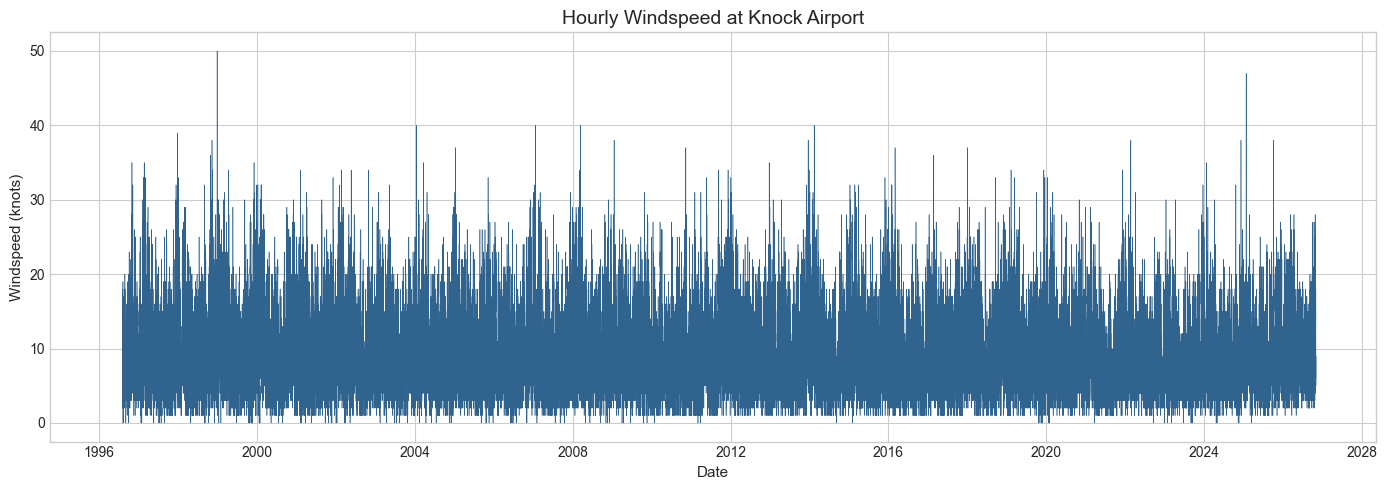

In [7]:
fig, ax = plt.subplots()
ax.plot(wind.index, wind, color="#30638e", lw=0.4)
ax.set(title="Hourly Windspeed at Knock Airport", xlabel="Date", ylabel="Windspeed (knots)")
plt.tight_layout()
plt.show()

## Rolling 24 hour windspeed plot

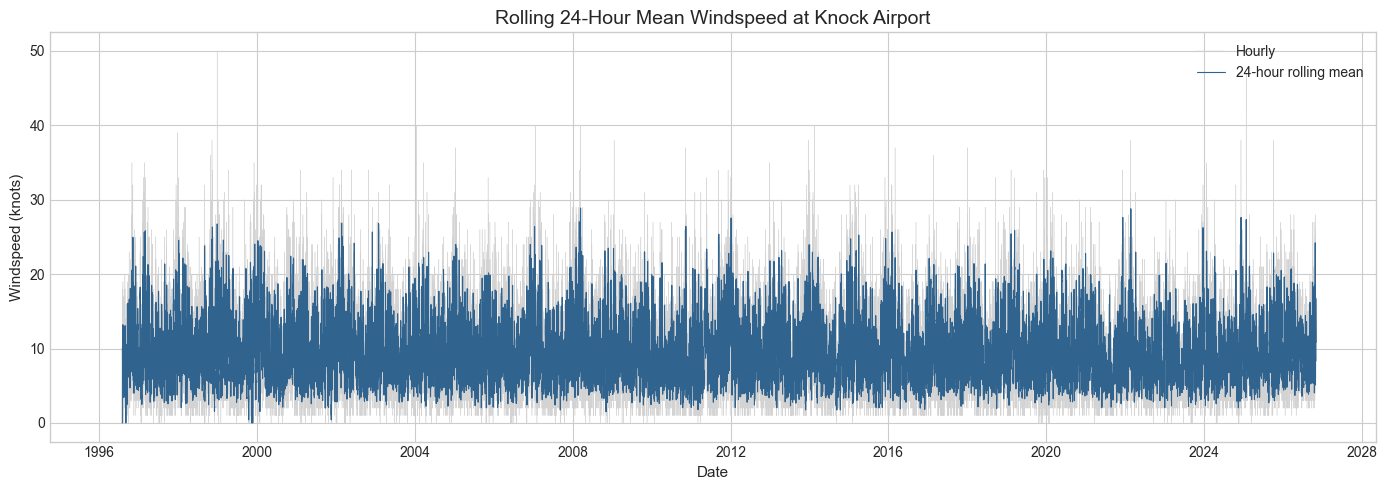

In [8]:
# Needs at least 12 valid readings in the window so gaps don't produce misleading averages
rolling_wind = wind.rolling(window=24, min_periods=12).mean()

fig, ax = plt.subplots()
ax.plot(wind.index, wind, color="lightgrey", lw=0.3, label="Hourly")
ax.plot(rolling_wind.index, rolling_wind, color="#30638e", lw=0.8, label="24-hour rolling mean")
ax.set(title="Rolling 24-Hour Mean Windspeed at Knock Airport", xlabel="Date", ylabel="Windspeed (knots)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## Daily maximum wind speed plot

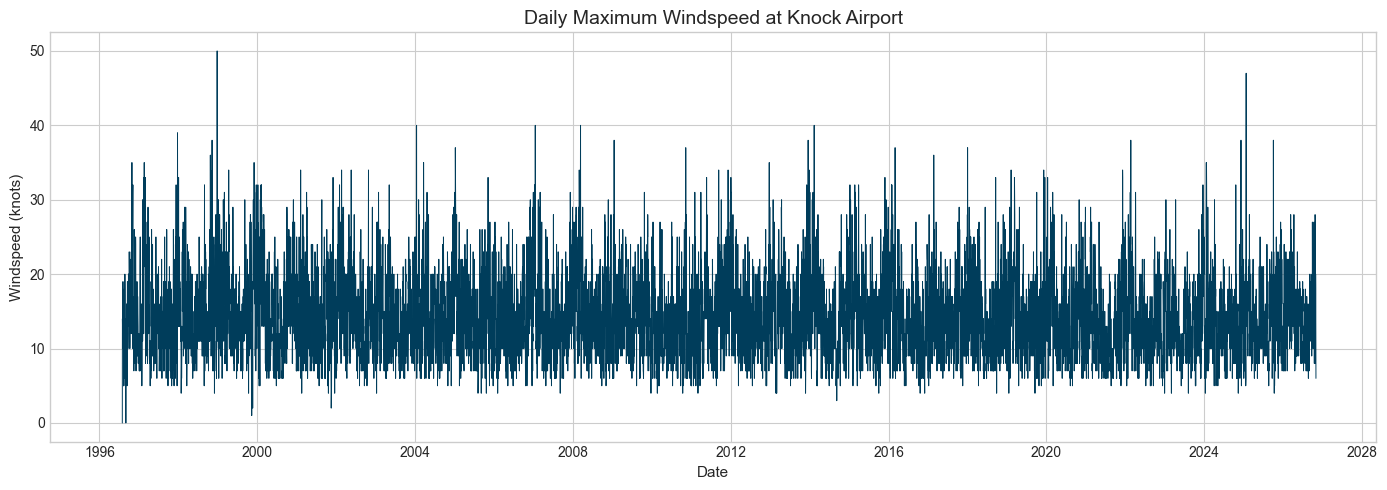

In [9]:
daily_max_wind = wind.resample("D").max()

fig, ax = plt.subplots()
ax.plot(daily_max_wind.index, daily_max_wind, color="#003d5b", lw=0.7)
ax.set(title="Daily Maximum Windspeed at Knock Airport", xlabel="Date", ylabel="Windspeed (knots)")
plt.tight_layout()
plt.show()

## Monthly mean of the daily max windspeeds plot

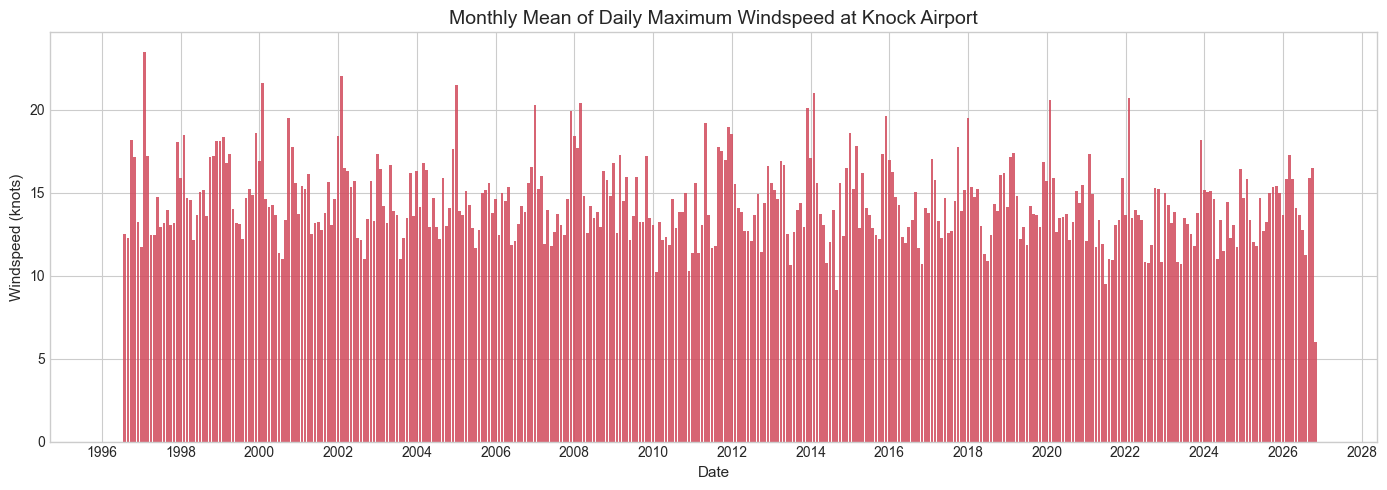

In [10]:
monthly_mean_max = daily_max_wind.resample("MS").mean()

fig, ax = plt.subplots()
ax.bar(monthly_mean_max.index, monthly_mean_max, width=25, color="#d1495b", alpha=0.85)
ax.set(title="Monthly Mean of Daily Maximum Windspeed at Knock Airport",
       xlabel="Date", ylabel="Windspeed (knots)")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()